# Optimisation à court terme des systèmes électriques — version corrigée

Ce TD aborde quatre problèmes de dispatch :
1. **Marché électrique simple** : dispatch économique, prix marginal, échanges entre zones et stockage ;
2. **Offres d’achat et de vente** : représentation d’un marché par des bids et maximisation du surplus social ;
3. **Réseau de transport (SciGRID)** : dispatch optimal sur un réseau maillé réaliste, prix nodaux, congestion, puis flux de puissance non linéaire ;
4. **Valeur de l’eau** : rôle de la valeur marginale du stock dans la gestion d’un stockage de longue durée.

**Dépendances :** `pypsa`, `numpy`, `pandas`, `matplotlib`, `cartopy` (exercice 3).

## Préparation commune

In [1]:
import logging
import warnings

# import de packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypsa

warnings.filterwarnings("ignore", category=DeprecationWarning)
pypsa.options.params.optimize.log_to_console = False

print("Version de PyPSA :", pypsa.__version__)

import logging

logging.getLogger("pypsa").setLevel(logging.ERROR)     # messages d'information masqués (on relance beaucoup de calculs)
logging.getLogger("linopy").setLevel(logging.WARNING)  # on garde les alertes, par exemple en cas d'infaisabilité


def copier_reseau(n):
    """Copie un réseau, y compris s'il a déjà été optimisé.

    Dans les versions récentes de PyPSA, `n.copy()` refuse de copier un réseau résolu
    tant que le modèle du solveur est attaché : on le détache d'abord.
    """
    if getattr(n, "model", None) is not None:
        n.model.solver_model = None
    return n.copy()


Version de PyPSA : 1.2.4


---

# Exercice 1 — Marché électrique simple

## Objectifs

- Comprendre comment le coût marginal des centrales détermine l’ordre d’appel ;
- relier le dispatch économique au prix marginal de l’électricité ;
- observer l’effet des échanges entre zones de marché ;
- étudier la demande flexible, les variations temporelles et le stockage.

On construit un modèle simplifé où les centrales sont représentées par des générateurs de puissance maximale donnée et de coût marginal constant. La demande est d'abord supposée inélastique : elle doit être satisfaite sous peine de rendre le modèle infaisable. Bien sur les capacités et consommations sont pédagogiques et ne représentent pas fidèlement les systèmes électriques réels.


## 1.0 Données du système

On définit les coûts marginaux (€/MWh) et les puissances nominales (MW) des générateurs. On considère cinq technologies : éolien, hydraulique, charbon, gaz et pétrole.

In [18]:
# Coûts marginaux en €/MWh
couts_marginaux = {
    "Wind": 0,
    "Hydro": 0,
    "Coal": 30,
    "Gas": 60,
    "Oil": 80,
}

# Puissances installées par zone (MW)
capacites = {
    "South Africa": {"Coal": 35000, "Wind": 3000, "Gas": 8000, "Oil": 2000},
    "Mozambique": {"Hydro": 1200},
    "Eswatini": {"Hydro": 600},
}

# Capacités d'interconnexion (MW)
interconnexions = {
    "South Africa": {"Mozambique": 500, "Eswatini": 250},
    "Mozambique": {"Eswatini": 100},
}

# Demande par zone (MW)
demandes = {"South Africa": 42000, "Mozambique": 650, "Eswatini": 250}

## 1.1 Une seule zone de marché, une période

On considère seulement l’Afrique du Sud. Le modèle choisit la production de chaque centrale pour satisfaire la demande au coût total minimal. Pour une demande inélastique, le prix marginal est généralement égal au coût marginal de la centrale marginale, c’est-à-dire la dernière centrale appelée.

In [19]:
# A faire: construire un réseau pypsa à 1 noeud représentant l'Afrique du Sud, 
# i.e sa consommation d'électricité et ses centrales. 

### DEBUT SOLUTION
zone = "South Africa"
n = pypsa.Network()
n.add("Bus", zone)

for technologie, puissance in capacites[zone].items():
    n.add(
        "Generator",
        f"{zone} {technologie}",
        bus=zone,
        p_nom=puissance,
        marginal_cost=couts_marginaux[technologie],
    )

n.add("Load", f"{zone} demande", bus=zone, p_set=demandes[zone])
n.optimize(solver_name="highs", api='direct')
### FIN SOLUTION


C:\Users\Mattéo\AppData\Local\Temp\ipykernel_31280\785088215.py:19: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs", api='direct')


('ok', 'unknown')

Examinons les capacités, la production et le prix marginal obtenus.

In [4]:
# A faire: recuperer les données interessantes stockées dans le réseau
# capacités, coûts marginaux, demande, production, prix, etc
### DEBUT SOLUTION
display(n.generators[["bus", "p_nom", "marginal_cost"]])
display(n.generators_t.p)
display(n.loads_t.p)
display(n.buses_t.marginal_price)
### FIN SOLUTION


,bus,p_nom,marginal_cost
name,,,
South Africa Coal,South Africa,35000.0,30.0
South Africa Wind,South Africa,3000.0,0.0
South Africa Gas,South Africa,8000.0,60.0
South Africa Oil,South Africa,2000.0,80.0


name,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil
snapshot,,,,
now,0.0,0.0,0.0,0.0


name,South Africa demande
snapshot,
now,42000.0


name
snapshot
now


**Questions.** 

Comparez la demande à la somme des capacités disponibles. 

Comment est répartie la production entre les centrales et comment interpréter le coût marginal au bus ? 

## 1.3 Deux zones reliées par une interconnexion

On ajoute à notre réseau le Mozambique, qui dispose d’une centrale hydraulique peu coûteuse. Pour modéliser l'interconnection, on ajoute un `Link`, qui représente ici une interconnexion contrôlable et sans pertes. Le paramètre `p_min_pu=-1` autorise un flux dans les deux sens.

In [5]:
# A faire: construire un nouveau réseau à 2 noeuds liés par une interconnection
### DEBUT SOLUTION
n = pypsa.Network()
zones = ["Mozambique", "South Africa"]

for zone in zones:
    n.add("Bus", zone)
    for technologie, puissance in capacites[zone].items():
        n.add(
            "Generator",
            f"{zone} {technologie}",
            bus=zone,
            p_nom=puissance,
            marginal_cost=couts_marginaux[technologie],
        )
    n.add("Load", f"{zone} demande", bus=zone, p_set=demandes[zone])

for zone, voisins in interconnexions.items():
    if zone not in zones:
        continue
    for voisin, puissance in voisins.items():
        if voisin in zones:
            n.add(
                "Link", f"{zone} - {voisin}",
                bus0=zone, bus1=voisin,
                p_nom=puissance, p_min_pu=-1,
            )

n.optimize(solver_name="highs")
### FIN SOLUTION


C:\Users\Mattéo\AppData\Local\Temp\ipykernel_31280\3842199756.py:28: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs")


('ok', 'unknown')

In [6]:
# A faire: récupérer la production, les prix, etc
### DEBUT SOLUTION
display(n.generators_t.p)
display(n.buses_t.marginal_price)
display(n.links_t.p0)
display(n.links_t.mu_lower)
### FIN SOLUTION


name,Mozambique Hydro,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil
snapshot,,,,,
now,0.0,0.0,0.0,0.0,0.0


name
snapshot
now


name,South Africa - Mozambique
snapshot,
now,0.0


name
snapshot
now


Le prix marginal peut différer entre les deux zones lorsque l’interconnexion est saturée. La différence de prix est liée à la valeur de la contrainte de transport. Tant que la capacité de transfert n’est pas limitante, les marchés peuvent avoir le même prix marginal dans ce modèle sans pertes.

## 1.4 Trois zones reliées

On ajoute l’Eswatini et ses capacités hydrauliques. La structure de code reste la même : création des bus, ajout des centrales et des demandes, puis ajout des interconnexions présentes entre les zones étudiées.

In [7]:
### DEBUT SOLUTION
n = pypsa.Network()
zones = ["Eswatini", "Mozambique", "South Africa"]

for zone in zones:
    n.add("Bus", zone)
    for technologie, puissance in capacites[zone].items():
        n.add(
            "Generator",
            f"{zone} {technologie}",
            bus=zone,
            p_nom=puissance,
            marginal_cost=couts_marginaux[technologie],
        )
    n.add("Load", f"{zone} demande", bus=zone, p_set=demandes[zone])

for zone, voisins in interconnexions.items():
    for voisin, puissance in voisins.items():
        if zone in zones and voisin in zones:
            n.add(
                "Link", f"{zone} - {voisin}",
                bus0=zone, bus1=voisin,
                p_nom=puissance, p_min_pu=-1,
            )

n.optimize(solver_name="highs")
### FIN SOLUTION


C:\Users\Mattéo\AppData\Local\Temp\ipykernel_31280\1108852092.py:26: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs")


('ok', 'unknown')

In [8]:
# A faire: récupérer les capacités, les prixs, etc
### DEBUT SOLUTION
display(n.generators_t.p)
display(n.buses_t.marginal_price)
display(n.links_t.p0)
display(n.links_t.mu_lower)
### FIN SOLUTION


name,Eswatini Hydro,Mozambique Hydro,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil
snapshot,,,,,,
now,0.0,0.0,0.0,0.0,0.0,0.0


name
snapshot
now


name,South Africa - Mozambique,South Africa - Eswatini,Mozambique - Eswatini
snapshot,,,
now,0.0,0.0,0.0


name
snapshot
now


## 1.5 Demande sensible au prix

Raffinons un peu nos hypothèses : on ajoute une demande (industrielle par exemple) élastique, c'est à dire sensible au prix. On peut la modélisée comme un générateur à dispatch négatif : une production négative correspond à une consommation. Son coût marginal négatif représente l’utilité marginale de la consommation.

In [9]:
# A faire : reprendre le modèle à un noeud du 1.1, et ajouter la demande élastique
### DEBUT SOLUTION
zone = "South Africa"
n = pypsa.Network()
n.add("Bus", zone)

for technologie, puissance in capacites[zone].items():
    n.add(
        "Generator", f"{zone} {technologie}",
        bus=zone, p_nom=puissance,
        marginal_cost=couts_marginaux[technologie],
    )

n.add("Load", f"{zone} demande inélastique", bus=zone, p_set=demandes[zone])
n.add(
    "Generator", f"{zone} demande industrielle",
    bus=zone, p_nom=8000,
    p_max_pu=0, p_min_pu=-1,
    marginal_cost=70,
)
n.optimize(solver_name="highs")
### FIN SOLUTION


C:\Users\Mattéo\AppData\Local\Temp\ipykernel_31280\2210003262.py:20: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs")


('ok', 'unknown')

In [10]:
# A faire : récuperer les données d'interet 
### DEBUT SOLUTION
display(n.generators_t.p)
display(n.buses_t.marginal_price)
### FIN SOLUTION


name,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil,South Africa demande industrielle
snapshot,,,,,
now,0.0,0.0,0.0,0.0,0.0


name
snapshot
now


**Questions** 

Comment la production et la consommation sont elles re-distribuées ? 

Pourquoi le charbon n'est pas utilisé pour satisfaire la demande industrielle ?

## 1.6 Plusieurs périodes : demande et vent variables

On considère maintenant quatre périodes. La disponibilité du vent varie, tout comme la demande.

In [20]:
p_max_pu = np.array([]) # à compléter 
p_set = np.array([]) # à compléter
zone = "South Africa"
n = pypsa.Network()
n.set_snapshots(range(4))
n.add("Bus", zone)

for technologie, puissance in capacites[zone].items():
    n.add(
        "Generator", f"{zone} {technologie}",
        bus=zone, p_nom=puissance,
        marginal_cost=couts_marginaux[technologie],
        p_max_pu=(p_max_pu if technologie == "Wind" else 1),
    )

n.add(
    "Load", f"{zone} demande",
    bus=zone,
    p_set=demandes[zone] + p_set,
)
n.optimize(solver_name="highs")



ValueError: Data for p_max_pu has length 0 but expected 4 for each snapshot.

In [12]:
# A faire : récuperer les données d'interet 
### DEBUT SOLUTION
display(n.generators_t.p)
display(n.buses_t.marginal_price)
### FIN SOLUTION


name,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil
snapshot,,,,
0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0


name
snapshot
0
1
2
3


## 1.7 Plusieurs périodes avec stockage

On ajoute une unité de stockage hydraulique par pompage. Elle peut charger lorsque l’électricité est relativement peu chère et décharger lorsque le système est tendu. Sa capacité énergétique vaut ici `p_nom × max_hours`.

In [13]:

zone = "South Africa"
n = pypsa.Network()
n.set_snapshots(range(4))
n.add("Bus", zone)

for technologie, puissance in capacites[zone].items():
    n.add(
        "Generator", f"{zone} {technologie}",
        bus=zone, p_nom=puissance,
        marginal_cost=couts_marginaux[technologie],
        p_max_pu=([0.3, 0.6, 0.4, 0.5] if technologie == "Wind" else 1),
    )

n.add(
    "Load", f"{zone} demande",
    bus=zone,
    p_set=demandes[zone] + np.array([0, 1000, 3000, 4000]),
)
# A faire : ajouter une unité de stockage de 6h et de puissance 1000 MW
### DEBUT SOLUTION
n.add(
    "StorageUnit", f"{zone} pompage-turbinage",
    bus=zone, p_nom=1000, max_hours=6,
)
### FIN SOLUTION
n.optimize(solver_name="highs")



C:\Users\Mattéo\AppData\Local\Temp\ipykernel_31280\4121037046.py:24: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs")


('ok', 'unknown')

In [14]:
# A faire : récupérer les données d'interet 
### DEBUT SOLUTION
display(n.generators_t.p)
display(n.storage_units_t.p)
display(n.storage_units_t.state_of_charge)
display(n.buses_t.marginal_price)
### FIN SOLUTION


name,South Africa Coal,South Africa Wind,South Africa Gas,South Africa Oil
snapshot,,,,
0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0


name,South Africa pompage-turbinage
snapshot,
0,0.0
1,0.0
2,0.0
3,0.0


name,South Africa pompage-turbinage
snapshot,
0,0.0
1,0.0
2,0.0
3,0.0


name
snapshot
0
1
2
3


## 1.8 Pour explorer : ordre de mérite, interconnexions, demande flexible, éolien et stockage

Pour faire varier facilement un paramètre, on encapsule la construction du réseau de l'Afrique du Sud dans une fonction (fournie). Elle peut ajouter une **centrale de délestage** fictive (coût très élevé) qui représente la demande non servie : sans elle, le modèle est infaisable quand la demande inélastique dépasse la capacité installée.

In [22]:
def reseau_afrique_du_sud(demande=42000, delestage=True, p_nom_vent=None, stockage=0, utilite_industrie=None, quatre_periodes=False):
    """Réseau de l'Afrique du Sud (un bus). Options :
    - delestage : ajoute une centrale de délestage à 1000 €/MWh ;
    - p_nom_vent : remplace la capacité éolienne installée ;
    - stockage : puissance (MW) d'un stockage par pompage de 6 h ;
    - utilite_industrie : ajoute une demande industrielle flexible de 8000 MW avec cette utilité marginale (€/MWh) ;
    - quatre_periodes : 4 périodes avec demande et vent variables (comme en 1.6).
    """
    zone = "South Africa"
    m = pypsa.Network()
    if quatre_periodes:
        m.set_snapshots(range(4))
    m.add("Bus", zone)
    for technologie, puissance in capacites[zone].items():
        options = {}
        if technologie == "Wind":
            puissance = p_nom_vent if p_nom_vent is not None else puissance
            if quatre_periodes:
                options["p_max_pu"] = [0.3, 0.6, 0.4, 0.5]
        m.add("Generator", f"{zone} {technologie}", bus=zone, p_nom=puissance,
              marginal_cost=couts_marginaux[technologie], **options)
    if delestage:
        m.add("Generator", "délestage", bus=zone, p_nom=50000, marginal_cost=1000)
    charge = demande + np.array([0, 1000, 3000, 4000]) if quatre_periodes else demande
    m.add("Load", "demande", bus=zone, p_set=charge)
    if utilite_industrie is not None:
        m.add("Generator", "demande industrielle", bus=zone, p_nom=8000,
              p_max_pu=0, p_min_pu=-1, marginal_cost=utilite_industrie)
    if stockage:
        m.add("StorageUnit", "pompage", bus=zone, p_nom=stockage, max_hours=6)
    m.optimize(solver_name="highs")
    return m


def tracer_ordre_de_merite(demande):
    """Ordre de mérite de l'Afrique du Sud : capacités cumulées en abscisse, coût marginal en ordonnée."""
    zone = "South Africa"
    techs = sorted(capacites[zone], key=lambda t: couts_marginaux[t])
    fig, ax = plt.subplots(figsize=(7, 3.5))
    debut = 0
    for t in techs:
        ax.bar(debut / 1e3, couts_marginaux[t], width=capacites[zone][t] / 1e3, align="edge", alpha=0.6, edgecolor="k", label=t)
        debut += capacites[zone][t]
    ax.axvline(demande / 1e3, color="r", ls="--", label="Demande")
    ax.set_xlabel("Capacité cumulée (GW)")
    ax.set_ylabel("Coût marginal (€/MWh)")
    ax.legend()
    plt.show()

### 1.8.a Ordre de mérite et prix en fonction de la demande

Le prix marginal est égal au coût marginal de la **centrale marginale**, donc il dépend de la position de la demande sur la courbe d'ordre de mérite. On trace d'abord cette courbe pour la demande de référence, puis le prix en faisant **varier la demande**.

> **! Prédisez :** le prix pour une demande de 37 000 MW, 46 500 MW et 50 000 MW (la capacité totale installée est de 48 000 MW).

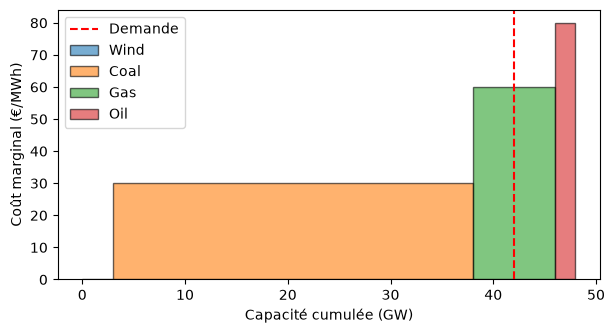

C:\Users\Mattéo\AppData\Local\Temp\ipykernel_31280\1473089167.py:31: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m.optimize(solver_name="highs")


KeyError: 'South Africa'

In [23]:
# A faire : (1) tracer l'ordre de mérite pour une demande de 42 000 MW ;
# (2) calculer le prix marginal pour des demandes de 2 000 à 52 000 MW (pas de 1 000 MW) et le tracer à l'aide matplotlib.
### DEBUT SOLUTION
tracer_ordre_de_merite(42000)

demandes_test = np.arange(2000, 52001, 1000)
prix_selon_demande = [
    reseau_afrique_du_sud(d).buses_t.marginal_price["South Africa"].iloc[0] for d in demandes_test
]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.step(demandes_test / 1e3, prix_selon_demande, where="mid")
ax.set_xlabel("Demande (GW)")
ax.set_ylabel("Prix marginal (€/MWh)")
ax.set_title("Prix marginal en fonction de la demande")
ax.grid(alpha=0.3)
plt.show()
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

- Le prix est **en escalier** : il vaut le coût marginal de la dernière centrale appelée. Demande < 3 GW : l'éolien suffit (prix nul) ; entre 3 et 38 GW : charbon marginal (30) ; entre 38 et 46 GW : gaz (60) ; entre 46 et 48 GW : pétrole (80) ; au-delà de 48 GW la capacité est épuisée et c'est la **centrale de délestage** qui fixe le prix (1000).
- Prédictions : 37 000 → 30 €/MWh ; 46 500 → 80 €/MWh ; 50 000 → 1000 €/MWh.
- Une très petite variation de la demande peut faire sauter le prix d'un palier à l'autre : le prix est **très volatil** près des changements de technologie. Sa valeur n'a rien à voir avec le coût *moyen* de production.
- Sans la centrale de délestage, le modèle serait **infaisable** à partir de 48 GW : il n'existe aucune solution qui satisfait la contrainte « demande = offre ».

### 1.8.b Combien vaut une interconnexion ?

On reprend le cas Mozambique–Afrique du Sud (1.3) en faisant varier la **capacité de la ligne** de 0 à 800 MW. Pour chaque valeur, on relève les prix des deux zones, le coût total d'exploitation et la **rente de congestion** : flux × écart de prix entre les deux extrémités (en €/h).

> **! Prédisez** : à partir de quelle capacité les deux prix deviennent-ils égaux ? Le Mozambique a 1200 MW d'hydraulique pour 650 MW de demande.

In [ ]:
def deux_zones(capacite_lien):
    """Mozambique (hydraulique) et Afrique du Sud reliés par un lien de capacité donnée (MW)."""
    m = pypsa.Network()
    for zone in ["Mozambique", "South Africa"]:
        m.add("Bus", zone)
        for technologie, puissance in capacites[zone].items():
            m.add("Generator", f"{zone} {technologie}", bus=zone, p_nom=puissance, marginal_cost=couts_marginaux[technologie])
        m.add("Load", f"{zone} demande", bus=zone, p_set=demandes[zone])
    m.add("Link", "interconnexion", bus0="Mozambique", bus1="South Africa", p_nom=capacite_lien, p_min_pu=-1)
    m.optimize(solver_name="highs")
    return m

In [ ]:
# TODO : balayer la capacité du lien (0, 100, ..., 800 MW) et tracer prix, coût total et rente de congestion.
### DEBUT SOLUTION
lignes = {}
for cap in range(0, 801, 100):
    m = deux_zones(cap)
    prix = m.buses_t.marginal_price.iloc[0]
    flux = m.links_t.p0["interconnexion"].iloc[0]
    lignes[cap] = {
        "Prix Mozambique": prix["Mozambique"],
        "Prix Afrique du Sud": prix["South Africa"],
        "Flux (MW)": flux,
        "Coût total (€/h)": m.objective,
        "Rente de congestion (€/h)": abs(flux * (prix["South Africa"] - prix["Mozambique"])),
    }
tableau = pd.DataFrame(lignes).T.rename_axis("Capacité du lien (MW)")
display(tableau.round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
tableau[["Prix Mozambique", "Prix Afrique du Sud"]].plot(ax=axes[0], ylabel="€/MWh", title="Prix")
tableau["Coût total (€/h)"].plot(ax=axes[1], ylabel="€/h", title="Coût total d'exploitation")
tableau["Rente de congestion (€/h)"].plot(ax=axes[2], ylabel="€/h", title="Rente de congestion")
plt.tight_layout()
plt.show()
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

- Tant que le lien est **saturé** (capacité < 550 MW, soit l'excédent hydraulique : 1200 − 650), le Mozambique reste à un prix nul (hydraulique bon marché inutilisée) alors que l'Afrique du Sud est à 60 : les prix sont découplés.
- À partir de **550 MW** (au-delà, la ligne n'est plus saturée et tout l'excédent est exporté), les deux prix deviennent égaux (60 €/MWh) : l'hydraulique est entièrement utilisée, c'est donc le gaz sud-africain qui fixe le prix des deux zones.
- Le **coût total diminue linéairement** avec la capacité (chaque MW exporté remplace du gaz à 60) puis devient constant : **rendements décroissants** de l'interconnexion, il est inutile de dépasser 550 MW.
- La **rente de congestion n'est pas monotone** : elle augmente avec la capacité (plus de flux × même écart de prix de 60) puis **s'effondre à zéro** quand les prix s'égalisent. Une ligne parfaitement dimensionnée n'a pas de rente de congestion.

### 1.8.c Demande flexible : retrouver une courbe de demande

En 1.5, la demande industrielle de 8000 MW est modélisée avec une utilité marginale de 70 €/MWh. On fait varier cette utilité de 0 à 120 €/MWh et on observe la **quantité consommée** : on reconstruit ainsi la courbe de demande de ce consommateur.

> **! Prédisez** : pour quelles utilités la demande industrielle passe-t-elle de 0 à une consommation non nulle ? Atteint-elle les 8000 MW ?

In [ ]:
# TODO : pour des utilités de 0 à 120 €/MWh (pas de 10), calculer la consommation de la demande industrielle (MW)
# et le prix marginal. Tracer la quantité consommée en fonction de l'utilité.
### DEBUT SOLUTION
lignes = {}
for u in range(0, 121, 10):
    m = reseau_afrique_du_sud(utilite_industrie=u)
    lignes[u] = {
        "Consommation industrielle (MW)": -m.generators_t.p["demande industrielle"].iloc[0],
        "Prix marginal (€/MWh)": m.buses_t.marginal_price["South Africa"].iloc[0],
    }
tableau = pd.DataFrame(lignes).T.rename_axis("Utilité marginale (€/MWh)")
display(tableau)

ax = tableau["Consommation industrielle (MW)"].plot(drawstyle="steps-post", figsize=(6, 3.5), ylabel="MW", title="Courbe de demande de l'industrie")
ax.grid(alpha=0.3)
plt.show()
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

- La consommation est **nulle** tant que l'utilité est inférieure à 60 €/MWh (le coût du gaz, marginal avec la demande de référence), passe à **4000 MW** entre 60 et 80 (il reste 4000 MW de gaz), puis à **6000 MW** au-delà de 80 (2000 MW de pétrole). Elle n'atteint **jamais 8000 MW** : la capacité installée est épuisée (48 000 MW pour 42 000 + 8000).
- On reconstruit une **courbe de demande en escalier** : un consommateur ne consomme que si sa disposition à payer dépasse le coût de la dernière unité servie. C'est exactement la logique des offres d'achat de l'exercice 2.
- Quand toute la capacité est utilisée, **c'est la demande flexible qui fixe le prix** (le prix marginal est alors égal à l'utilité marginale du dernier consommateur servi).

### 1.8.d Beaucoup d'éolien : baisse des prix et « cannibalisation »

On reprend le modèle à 4 périodes (1.6) et on augmente la capacité éolienne. On calcule le **prix moyen** et le **prix capté par l'éolien** (revenu moyen par MWh produit).

> **! Prédisez** : le prix capté par l'éolien est-il supérieur, égal ou inférieur au prix moyen ? Que se passe-t-il pour de très grandes capacités ?

In [ ]:
# TODO : pour des capacités éoliennes de 3, 10, 20, 30, 50, 80 et 120 GW, calculer le prix moyen, le prix capté par l'éolien,
# l'énergie écrêtée (MWh) et le coût total d'exploitation.
### DEBUT SOLUTION
disponibilite = np.array([0.3, 0.6, 0.4, 0.5])
lignes = {}
for p_vent in [3000, 10000, 20000, 30000, 50000, 80000, 120000]:
    m = reseau_afrique_du_sud(p_nom_vent=p_vent, quatre_periodes=True)
    prix = m.buses_t.marginal_price["South Africa"]
    vent = m.generators_t.p["South Africa Wind"]
    lignes[p_vent / 1e3] = {
        "Prix moyen (€/MWh)": prix.mean(),
        "Prix capté par l'éolien (€/MWh)": (vent * prix).sum() / vent.sum(),
        "Énergie écrêtée (MWh)": (p_vent * disponibilite - vent.values).sum(),
        "Coût d'exploitation (M€)": m.objective / 1e6,
    }
tableau = pd.DataFrame(lignes).T.rename_axis("Capacité éolienne (GW)")
tableau["Facteur de valeur"] = tableau["Prix capté par l'éolien (€/MWh)"] / tableau["Prix moyen (€/MWh)"]
display(tableau.round(2))
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

- Le **prix moyen baisse** quand la capacité éolienne augmente : l'éolien (coût marginal nul) se place en tête de l'ordre de mérite et **déplace** les centrales plus chères (*merit-order effect*). On passe de 70 €/MWh (3 GW) à 30 €/MWh (30 GW, le charbon devient marginal) puis proche de 0.
- Le **prix capté par l'éolien est inférieur au prix moyen** pour les grandes capacités (facteur de valeur < 1) : l'éolien produit surtout quand le vent souffle, c'est-à-dire quand **tous les parcs produisent en même temps** et font baisser le prix. C'est la **cannibalisation** : plus on en installe, moins chaque MWh vaut.
- À très grande capacité, une partie de la production est **écrêtée** et les prix tombent à zéro pendant plusieurs périodes : sans stockage ni flexibilité de la demande, l'énergie excédentaire ne vaut rien.
- Le coût d'exploitation diminue mais **l'investissement n'est pas pris en compte** ici : en pratique, la baisse du prix capté décourage de nouveaux investissements (voir TD long terme).

### 1.8.e Le stockage aplatit les prix… jusqu'à un certain point

On reprend le modèle à 4 périodes avec stokage (1.7) et on fait varier la **puissance du stockage** (de 0 à 4000 MW, avec 6 h de capacité d'énergie).

> **! Prédisez** : le coût d'exploitation baisse-t-il linéairement avec la puissance du stockage ? Que devient l'écart de prix entre la période la plus chère et la moins chère ?

In [ ]:
# TODO : pour des puissances de stockage de 0 à 4000 MW (pas de 500 MW), relever le coût d'exploitation et l'écart de prix max-min.
### DEBUT SOLUTION
lignes = {}
for p_stockage in range(0, 4001, 500):
    m = reseau_afrique_du_sud(quatre_periodes=True, stockage=p_stockage)
    prix = m.buses_t.marginal_price["South Africa"]
    lignes[p_stockage] = {
        "Coût d'exploitation (M€)": m.objective / 1e6,
        "Écart de prix max-min (€/MWh)": prix.max() - prix.min(),
        **{f"Prix période {t}": prix.iloc[t] for t in range(4)},
    }
tableau = pd.DataFrame(lignes).T.rename_axis("Puissance du stockage (MW)")
display(tableau.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
tableau["Coût d'exploitation (M€)"].plot(ax=axes[0], marker="o", title="Coût d'exploitation")
tableau["Écart de prix max-min (€/MWh)"].plot(ax=axes[1], marker="o", title="Écart de prix max-min")
plt.tight_layout()
plt.show()
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

- Le coût diminue avec la puissance du stockage mais avec des **rendements décroissants** : au-delà d'un certain seuil (ici 2000 MW), plus de stockage ne sert plus à rien car **les prix sont déjà égalisés** entre les périodes : il n'y a plus de différence de prix à exploiter (arbitrage).
- Le stockage réduit l'écart de prix **jusqu'à l'annuler** : sa valeur provient justement de cet écart. Cela illustre un phénomène général de **cannibalisation du stockage** : plus il y a de stockage, plus la valeur de chaque MW supplémentaire diminue.
- Rappel de l'énoncé de synthèse : le stockage ne réduit pas le prix à *toutes* les périodes : il l'augmente aux périodes où il charge (demande supplémentaire) et le diminue aux périodes où il décharge.

**Questions de synthèse**
- Pourquoi le prix marginal peut-il dépasser le coût moyen de production ?
- Quand une interconnexion ne permet-elle plus d’égaliser les prix ?
- Pourquoi le stockage peut-il réduire le recours à une centrale coûteuse sans nécessairement réduire le prix à toutes les périodes ?


---

# Exercice 2 — Offres d’achat et de vente

## Objectifs

Modéliser un marché électrique à partir d’offres de vente et d’achat. Les quantités sont acceptées par optimisation du surplus social, sous contrainte d’équilibre entre production et consommation. On compare ensuite un marché intégré à deux zones séparées, puis reliées par une interconnexion.

Une seule période horaire est représentée : les MW et les MWh ont donc la même valeur numérique dans cet exemple.


## 2.0 Données des offres

On fait l'hypothèses d'offres de vente classées par prix croissant et d'offres d’achat par disposition à payer décroissante. La quantité de chaque offre constitue une borne maximale, pas une obligation d’acceptation.

In [24]:
offres_vente = {
    "quantite": [120, 100, 50, 60, 70, 60, 50],
    "prix": [0, 15, 20, 36, 60, 150, 200],
    "zone": ["nord", "sud", "nord", "nord", "sud", "nord", "sud"],
}
offres_achat = {
    "quantite": [250, 80, 20, 40, 60],
    "prix": [200, 90, 75, 65, 24],
    "zone": ["sud", "nord", "nord", "sud", "sud"],
}

## 2.1 Représenter les courbes agrégées

On peut visualiser ces offres/demandes pour estimer l'allocation optimales des ressources. L’optimisation permettra ensuite de calculer précisément les quantités acceptées.

In [ ]:
plt.figure(figsize=(8, 4))
plt.step(
    np.cumsum([0] + offres_vente["quantite"]),
    [offres_vente["prix"][0]] + offres_vente["prix"],
    where="post", label="Offre",
)
plt.step(
    np.cumsum([0] + offres_achat["quantite"]),
    [offres_achat["prix"][0]] + offres_achat["prix"],
    where="post", label="Demande",
)
plt.xlabel("Quantité cumulée (MW)")
plt.ylabel("Prix (€/MWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 2.2 Marché intégré à une seule zone

Chaque offre de vente est représentée par un générateur de coût marginal égal à son prix d’offre. Chaque offre d’achat est représentée par un générateur de signe négatif, dont le coût marginal est l’opposé de la disposition à payer. Minimiser le coût total équivaut alors à maximiser le surplus social.

In [25]:
# A faire : Construire un réseau qui reproduit notre set-up
# (avec des générateurs à coûts margianux négatifs pour les offres d'achat
### DEBUT SOLUTION
n = pypsa.Network()
n.add("Bus", "marche unique")

n.add(
    "Generator",
    name=[f"vente_{i}" for i in range(len(offres_vente["quantite"]))],
    bus="marche unique",
    marginal_cost=offres_vente["prix"],
    p_nom=offres_vente["quantite"],
)
n.add(
    "Generator",
    name=[f"achat_{i}" for i in range(len(offres_achat["quantite"]))],
    bus="marche unique",
    p_nom=offres_achat["quantite"],
    marginal_cost=[-p for p in offres_achat["prix"]],
    sign=-1,
)
n.optimize(solver_name="highs")
### FIN SOLUTION


C:\Users\Mattéo\AppData\Local\Temp\ipykernel_31280\1429043801.py:22: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs")


('ok', 'unknown')

### Lire la solution

In [ ]:
# A faire : récupérer la dispatch, les prix et le coût total
### DEBUT SOLUTION
display(n.generators_t.p)
display(n.buses_t.marginal_price)
display(n.model.objective)
### FIN SOLUTION


Les offres de vente acceptées ont une production positive. Les offres d’achat acceptées ont aussi une puissance `p` **positive** (c’est la quantité achetée) : c’est l’attribut `sign=-1` qui indique que cette puissance est **consommée** dans l’équilibre du bus. Le prix marginal du bus donne le prix d’équilibre du marché intégré. L'optimisation donne exactement le résultat prévu. 

## 2.3 Deux zones sans interconnexion

On affecte chaque offre à une zone (nord ou sud). Sans interconnexion, chaque zone doit équilibrer localement les offres d’achat et de vente qui lui sont attribuées.

In [26]:
# A faire : construire un second réseau, où cette fois les offres sont attribués
# à une zone (2 bus, nord et sud) 
### DEBUT SOLUTION
n2 = pypsa.Network()
n2.add("Bus", "nord")
n2.add("Bus", "sud")

n2.add(
    "Generator",
    name=[f"vente_{i}" for i in range(len(offres_vente["quantite"]))],
    bus=offres_vente["zone"],
    marginal_cost=offres_vente["prix"],
    p_nom=offres_vente["quantite"],
)
n2.add(
    "Generator",
    name=[f"achat_{i}" for i in range(len(offres_achat["quantite"]))],
    bus=offres_achat["zone"],
    p_nom=offres_achat["quantite"],
    marginal_cost=[-p for p in offres_achat["prix"]],
    sign=-1,
)
n2.optimize(solver_name="highs")
### FIN SOLUTION


C:\Users\Mattéo\AppData\Local\Temp\ipykernel_31280\3285003995.py:23: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n2.optimize(solver_name="highs")


('ok', 'unknown')

In [ ]:
# A Faire récupérer les résultats et comparer
### DEBUT SOLUTION
display(n2.buses_t.marginal_price)
display(n.objective)
display(n2.objective)
### FIN SOLUTION


## 2.4 Ajouter une interconnexion

Une ligne de 100 MW relie le nord et le sud. Les possibilités d’échange augmentent, mais restent limitées par la capacité de transport.

In [ ]:
# A faire : ajouter au réseau à deux bus une interconnection de 100 MW
# et comparer les résultats
### DEBUT SOLUTION
n2.add("Line", "interconnexion", bus0="nord", bus1="sud", s_nom=100)
n2.optimize(solver_name="highs")
display(n2.objective)
display(n2.buses_t.marginal_price)
### FIN SOLUTION


## 2.6 Pour explorer : surplus, effets redistributifs et capacité d'interconnexion

#### 2.6.a Décomposer le bien-être social

Dans le modèle, minimiser le coût total équivaut à **maximiser le surplus social**. On peut le décomposer en trois parts :

- **surplus des consommateurs** : $\sum (\text{disposition à payer} - \text{prix}) \times \text{quantité achetée}$ ;
- **surplus des producteurs** : $\sum (\text{prix} - \text{prix d'offre}) \times \text{quantité vendue}$ ;
- **rente de congestion** : flux $\times$ écart de prix entre les deux zones (lorsqu'une ligne existe).

La fonction suivante (fournie) calcule ces grandeurs. Elle suppose que les offres de vente s'appellent `vente_i` et les offres d'achat `achat_i`.

> **Convention de signe.** Pour les offres d'achat, on a utilisé `sign=-1` : la puissance `p` reste **positive** (quantité achetée) et c'est le signe qui indique que cette puissance est *consommée* dans l'équilibre du bus.

In [ ]:
def surplus(m):
    """Surplus des consommateurs (SC), des producteurs (SP), rente de congestion et bien-être social."""
    p = m.generators_t.p.iloc[0]
    prix = m.buses_t.marginal_price.iloc[0]
    g = m.generators
    prix_bus = g.bus.map(prix)
    ventes = g.index.str.startswith("vente")
    achats = g.index.str.startswith("achat")
    sp = ((prix_bus - g.marginal_cost) * p)[ventes].sum()
    sc = ((-g.marginal_cost - prix_bus) * p)[achats].sum()   # -marginal_cost = disposition à payer
    rente = 0.0
    if len(m.lines):
        ligne = m.lines.iloc[0]
        rente = abs(m.lines_t.p0.iloc[0, 0] * (prix[ligne.bus1] - prix[ligne.bus0]))
    return pd.Series({"SC": sc, "SP": sp, "Rente de congestion": rente, "Bien-être social": sc + sp + rente})

In [ ]:
# A faire : calculer la décomposition du bien-être pour le marché intégré (n), les deux zones isolées (réseau n2 construit en 2.4,
# avant l'ajout de la ligne : reconstruisez-le si besoin) et les deux zones avec la ligne de 100 MW (2.5).
# Vérifier que SC + SP + rente = -objectif.
### DEBUT SOLUTION
def marche_deux_zones(s_nom=None):
    m = pypsa.Network()
    m.add("Bus", "nord")
    m.add("Bus", "sud")
    m.add("Generator", name=[f"vente_{i}" for i in range(len(offres_vente["quantite"]))], bus=offres_vente["zone"],
          marginal_cost=offres_vente["prix"], p_nom=offres_vente["quantite"])
    m.add("Generator", name=[f"achat_{i}" for i in range(len(offres_achat["quantite"]))], bus=offres_achat["zone"],
          p_nom=offres_achat["quantite"], marginal_cost=[-p for p in offres_achat["prix"]], sign=-1)
    if s_nom is not None:
        m.add("Line", "interconnexion", bus0="nord", bus1="sud", s_nom=s_nom)
    m.optimize(solver_name="highs")
    return m

cas = {
    "Marché intégré": n,
    "Deux zones isolées": marche_deux_zones(),
    "Deux zones + ligne 100 MW": marche_deux_zones(100),
}
bilan = pd.DataFrame({nom: surplus(m) for nom, m in cas.items()}).T
bilan["-objectif"] = [-m.objective for m in cas.values()]
display(bilan.round(0))
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

- La somme SC + SP + rente est **exactement égale à l'opposé de l'objectif** : c'est la définition du surplus social dans ce modèle.
- Le marché **intégré** (un seul prix) donne le surplus maximal. Le découpage en deux zones **sans ligne** détruit environ 30 % du surplus (certaines transactions avantageuses entre zones sont impossibles), et le prix devient très différent dans les deux zones. La ligne de 100 MW récupère la quasi-totalité de la perte.
- Notez que les prix dans les zones isolées sont extrêmes (un prix nul au nord, 200 €/MWh au sud) : **un prix peut valoir la disposition à payer du consommateur marginal** quand l'offre manque.

#### 2.6.b Faire varier la capacité de la ligne

> **! Prédisez** : à partir de quelle capacité les deux prix sont-ils égaux ? Le surplus des *consommateurs* du sud augmente-t-il toujours avec la capacité ?

In [ ]:
# TODO : pour des capacités de ligne de 0, 25, 50, 100, 150, 200 et 300 MW, tracer le bien-être social, le surplus des
# consommateurs, celui des producteurs, la rente de congestion et les prix des deux zones.
### DEBUT SOLUTION
lignes = {}
for cap in [0, 25, 50, 100, 150, 200, 300]:
    m = marche_deux_zones(cap)
    prix = m.buses_t.marginal_price.iloc[0]
    lignes[cap] = {**surplus(m).to_dict(), "Prix nord": prix["nord"], "Prix sud": prix["sud"]}
tableau = pd.DataFrame(lignes).T.rename_axis("Capacité de ligne (MW)")
display(tableau.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
tableau[["SC", "SP", "Rente de congestion", "Bien-être social"]].plot(ax=axes[0], marker="o", title="Surplus")
tableau[["Prix nord", "Prix sud"]].plot(ax=axes[1], marker="o", title="Prix (€/MWh)")
plt.tight_layout()
plt.show()
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

- Le bien-être social **augmente avec la capacité** puis **plafonne** à la valeur du marché intégré dès que la ligne n'est plus saturée (150 MW ici) : les prix s'égalisent à 60 €/MWh.
- Le surplus n'est pas réparti de façon uniforme : **une petite ligne (25-50 MW) fait baisser le surplus des consommateurs** (les consommateurs du nord paient plus cher, car la ligne leur fait exporter de l'électricité bon marché) mais augmente celui des producteurs et crée une rente de congestion. L'interconnexion augmente le surplus total mais crée des **gagnants et des perdants** : c'est un enjeu politique réel des couplages de marchés.
- La rente de congestion est maximale pour une capacité intermédiaire puis tombe à zéro : un opérateur de réseau qui maximiserait cette rente aurait intérêt à **limiter** la capacité (conflit d'intérêts), alors que le bien-être social serait maximal avec une ligne plus grande.

#### 2.6.c Effet d'une offre à prix nul (énergies renouvelables fatales)

On ajoute au marché intégré une offre de vente de **150 MW à 0 €/MWh** (parc éolien/solaire subventionné ou production fatale). On compare le prix, le surplus des consommateurs et celui des producteurs.

In [ ]:
# TODO : ajouter l'offre au marché intégré (réseau n copié), le résoudre, puis comparer prix et surplus avec la situation de départ.
### DEBUT SOLUTION
n_enr = copier_reseau(n)
n_enr.add("Generator", "vente_enr", bus="marche unique", p_nom=150, marginal_cost=0)
n_enr.optimize(solver_name="highs")

comparaison = pd.DataFrame({"sans offre à 0": surplus(n), "avec offre à 0": surplus(n_enr)})
comparaison.loc["Prix (€/MWh)"] = [n.buses_t.marginal_price.iloc[0, 0], n_enr.buses_t.marginal_price.iloc[0, 0]]
display(comparaison.round(1))
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

Le prix **chute** (de 60 à 24 €/MWh) : les offres de vente les plus chères sont évincées. Les **consommateurs gagnent** beaucoup, les **producteurs conventionnels perdent** (ils vendent moins et moins cher) alors que le bien-être total augmente. C'est le **merit-order effect** : l'arrivée d'une capacité à coût marginal quasi nul tire les prix vers le bas, ce qui pose ensuite la question de la rentabilité des centrales conventionnelles (voir 1.8.d et le TD long terme).

**Questions de synthèse**

- Pourquoi le « bien-être social » est-il identique à l'opposé de la fonction objectif ?
- Pourquoi le découpage en zones peut-il réduire le surplus social ?
- Dans quel cas les prix des deux zones sont-ils égaux ?
- Comment interpréter une ligne saturée et un écart de prix persistant entre les deux zones ?


---

# Exercice 3 — Réseau de transport : dispatch optimal puis flux de puissance (SciGRID)

## Objectifs

Jusqu'ici, un « marché » était un seul nœud ou quelques zones reliées par des interconnexions simples. Ici, on étudie un **vrai réseau maillé** : le réseau de transport allemand (environ 600 nœuds, 850 lignes), avec ses centrales, son stockage par pompage et sa charge. Vous allez :

1. optimiser le dispatch avec un **flux de puissance optimal linéaire** (LOPF) ;
2. interpréter les **prix nodaux** (LMP, *locational marginal prices*) et la **congestion** ;
3. mesurer l'**écrêtement** de l'éolien dû au réseau ;
4. **expérimenter** : marge de sécurité N-1, « plaque de cuivre », doublement de l'éolien, cas infaisable.

Cet exercice reprend l'exemple `scigrid-lopf-then-pf` de la documentation PyPSA.

## Données

- **Réseau :** basé sur [SciGRID](https://openenergyplatform.org/factsheets/models/22/), lui-même issu d'OpenStreetMap.
- **Charge :** répartie proportionnellement au PIB et à la population des régions NUTS3 ; série temporelle horaire ENTSO-E, multipliée par 1,12.
- **Centrales conventionnelles :** liste de la BNetzA (agence fédérale allemande des réseaux).
- **Éolien et solaire :** capacités installées fin 2014 (EEG Stammdaten, EnergyMap) ; séries temporelles générées avec l'outil REatlas.
- **Période :** la journée du **1er janvier 2011**, pas horaire (24 instants).

> ⚠️ **Limites.** Ces données ne sont plus mises à jour et servent uniquement à illustrer les capacités de PyPSA ; elles ne conviennent pas à la recherche (voir [PyPSA-Eur](https://github.com/PyPSA/pypsa-eur) pour un modèle maintenu). Parmi les approximations : transformateurs 220/380 kV et connexions manquantes dans OSM, congestions inattendues dans certaines régions, frontières et pays voisins non représentés, centrales hydrauliques approximatives, coûts marginaux illustratifs, pas de coûts de démarrage ni de rampes, un seul jour non représentatif.

## 3.1 Charger et explorer les données

Le réseau est fourni par PyPSA. On commence par visualiser où se trouvent la **charge** et les **moyens de production**.

In [17]:
import cartopy.crs as ccrs

n_sg = pypsa.examples.scigrid_de()
print(n_sg)

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Mattéo\\AppData\\Local\\pypsa\\pypsa\\Cache\\examples\\v1.2.4\\scigrid_de.nc'

In [ ]:
fig, ax = plt.subplots(1, 1, subplot_kw={"projection": ccrs.EqualEarth()})

repartition_charge = n_sg.loads_t.p_set.loc[n_sg.snapshots[0]].groupby(n_sg.loads.bus).sum()
n_sg.plot(bus_size=repartition_charge / 30000, ax=ax, title="Répartition de la charge")
plt.show()

In [ ]:
display(n_sg.generators.groupby("carrier")["p_nom"].sum().round(1).rename("Capacité (MW)"))
display(n_sg.storage_units.groupby("carrier")["p_nom"].sum().round(1).rename("Capacité (MW)"))
display(n_sg.generators.groupby("carrier")["marginal_cost"].mean().round(1).rename("Coût marginal moyen (€/MWh)"))

In [ ]:
techs = ["Gas", "Brown Coal", "Hard Coal", "Wind Offshore", "Wind Onshore", "Solar"]
n_cols = 3
n_rows = -(-len(techs) // n_cols)   # division entière par excès

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, subplot_kw={"projection": ccrs.EqualEarth()})
fig.set_size_inches(6 * n_cols, 6 * n_rows)

for ax, tech in zip(axes.flat, techs):
    gens = n_sg.generators[n_sg.generators.carrier == tech]
    repartition = gens.groupby("bus")["p_nom"].sum().reindex(n_sg.buses.index, fill_value=0)
    n_sg.plot(ax=ax, bus_size=repartition / 20000)
    ax.set_title(tech)
fig.tight_layout()
plt.show()

**Questions**
1. Où se situent les principaux centres de consommation ? Où sont les gisements de production éolienne (terrestre et en mer), solaire, charbon (lignite et houille) ?
2. Repérez l'écart géographique entre production à bas coût et consommation. Quelle conséquence anticipez-vous pour le réseau ?
3. Classez les technologies par coût marginal moyen : cet ordre est-il cohérent avec ce que vous avez vu à l'exercice 1 ?

**Éléments de réponse** *(cellule de correction)*

1. La **charge** est concentrée dans les zones densément peuplées et industrielles (Ruhr/Rhénanie, Rhin-Main, Stuttgart, Munich, Berlin, Hambourg). L'**éolien** est surtout dans le nord (côtes, mer du Nord et mer Baltique pour l'offshore), le **solaire** surtout dans le sud, le **lignite** dans les bassins de Rhénanie (ouest) et de Lusace (est), la **houille** et le **gaz** sont plus diffus, près des centres de consommation et des ports.
2. Une grande partie de la production à très bas coût (éolien du nord, lignite) est **éloignée** des principaux centres de consommation (ouest et sud) : il faudra transporter de l'énergie du nord vers le sud, ce qui peut saturer les lignes nord-sud.
3. L'ordre croissant des coûts marginaux (renouvelables et nucléaire/fil de l'eau très bas, puis lignite, houille, gaz) est celui de l'**ordre de mérite** vu à l'exercice 1.

## 3.2 Optimiser le dispatch : le LOPF

### Principe

Le LOPF (*linear optimal power flow*) minimise le coût de production sous contraintes :
- équilibre offre-demande à chaque **nœud** ;
- limites des centrales ;
- lois de Kirchhoff, approchées par les **équations de flux continu (DC)** : le flux sur une ligne est proportionnel à la différence d'angle de tension entre ses extrémités (le courant se répartit **selon l'impédance des lignes**, on ne peut pas choisir librement le chemin, contrairement à un lien `Link`) ;
- capacité des lignes : $|f_\ell| \le s_{\text{nom},\ell} \times s_{\text{max pu},\ell}$.

### La marge N-1

Pour représenter approximativement la **sécurité N-1** (le réseau doit supporter la perte d'une ligne) et laisser de la place pour la puissance réactive, on interdit de charger les lignes au-delà de **70 %** de leur capacité thermique (`s_max_pu = 0.7`). Quelques lignes sont infaisables sans petites extensions : on augmente légèrement leur capacité.

### Horizon glissant

On optimise la journée **4 pas de temps à la fois** (`optimize_with_rolling_horizon`) : cela rend les calculs plus rapides, et c'est ainsi que fonctionne une exploitation réelle (on ne connaît pas toute la journée à l'avance). L'état du stockage est transmis d'une fenêtre à la suivante (voir l'exercice 4 pour les conséquences de cette miopie).

> Ce calcul prend de l'ordre de 30 secondes.

In [ ]:
facteur_contingence = 0.7
n_sg.lines.s_max_pu = facteur_contingence
n_sg.lines.loc[["316", "527", "602"], "s_nom"] = 1715      # petites extensions pour éviter l'infaisabilité

n_vierge = n_sg.copy()    # réseau non optimisé, conservé pour les expériences de la section 3.7

In [ ]:
n_sg.optimize.optimize_with_rolling_horizon(horizon=4, overlap=0, solver_name="highs")

### Toujours vérifier que le résultat est cohérent

L'optimisation à horizon glissant **n'interrompt pas** le calcul si une fenêtre est infaisable : elle peut renvoyer des productions nulles sans erreur visible. Avant d'analyser quoi que ce soit, on vérifie que **production + déstockage = charge** à chaque instant (fonction fournie).

In [ ]:
def verifier_bilan(m, tolerance=1.0):
    """Vérifie que production + déstockage = charge à chaque pas de temps (en MW). Renvoie True si tout va bien."""
    production = m.generators_t.p.sum(axis=1) + m.storage_units_t.p.sum(axis=1)
    ecart = (production - m.loads_t.p_set.sum(axis=1)).abs()
    if (ecart > tolerance).any():
        print(f"⚠️ Bilan non respecté à {int((ecart > tolerance).sum())} pas de temps sur {len(ecart)} : "
              f"le calcul a probablement été infaisable. Résultats inutilisables.")
        return False
    print("✓ Bilan offre-demande respecté à chaque pas de temps.")
    return True

In [ ]:
verifier_bilan(n_sg)

## 3.3 Le dispatch par technologie et le stockage

On trace la production horaire cumulée par technologie (les technologies de moins de 1,7 GW de pic sont omises pour la lisibilité), puis le comportement du **stockage par pompage**.

In [ ]:
# A faire : calculer la production par technologie (MW), retirer les petites technologies et tracer la dispatch en aires empilées (GW).
### DEBUT SOLUTION
p_par_carrier = n_sg.generators_t.p.T.groupby(n_sg.generators.carrier).sum().T
petites = p_par_carrier.max()[p_par_carrier.max() < 1700].index
p_par_carrier = p_par_carrier.drop(columns=petites)

couleurs = {
    "Brown Coal": "brown", "Hard Coal": "k", "Nuclear": "r", "Run of River": "green",
    "Wind Onshore": "blue", "Solar": "yellow", "Wind Offshore": "cyan", "Waste": "orange", "Gas": "orange",
}
ordre = ["Nuclear", "Run of River", "Brown Coal", "Hard Coal", "Gas", "Wind Offshore", "Wind Onshore", "Solar"]
p_par_carrier = p_par_carrier[[c for c in ordre if c in p_par_carrier.columns]]

fig, ax = plt.subplots(figsize=(9, 4))
p_par_carrier.div(1e3).plot(kind="area", ax=ax, lw=0, color=[couleurs[c] for c in p_par_carrier.columns], alpha=0.7)
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, 1.02, 1, 0.2), frameon=False)
ax.set_ylabel("GW")
ax.set_xlabel("")
plt.show()
### FIN SOLUTION

In [ ]:
# A faire: tracer la dispatch (turbine et soutirage) des stations de pompage
### DEBUT SOLUTION
fig, ax = plt.subplots(figsize=(9, 3.5))
n_sg.storage_units_t.p.sum(axis=1).plot(label="Puissance du pompage-turbinage (MW, >0 = turbinage)", ax=ax)
n_sg.storage_units_t.state_of_charge.sum(axis=1).plot(label="Énergie stockée (MWh)", ax=ax)
ax.axhline(0, color="k", lw=0.5, ls="--")
ax.legend()
ax.set_xlabel("")
plt.show()
### FIN SOLUTION

**Questions**
1. Quelles technologies tournent quasiment à puissance constante (« base ») ? Lesquelles s'ajustent (« suiveuses ») ? Reliez-le à leur coût marginal.
2. À quels moments le stockage par pompage charge-t-il, et décharge-t-il ? Pourquoi ?
3. L'énergie stockée en fin de journée est-elle égale à celle du début ? Que cela change-t-il pour l'interprétation ?

**Éléments de réponse** *(cellule de correction)*

1. Le **nucléaire**, le **fil de l'eau** et le **lignite** (coût marginal bas) fournissent la base ; la **houille** et le **gaz** (coût plus élevé) suivent la charge ; l'éolien et le solaire suivent la **disponibilité de la ressource**, pas la charge.
2. Le pompage charge la **nuit**, quand la demande et donc les prix sont bas, et turbine pendant les pointes du matin/soir : c'est de l'**arbitrage** temporel, comme à l'exercice 1.7.
3. Sur une journée avec horizon glissant, l'état du stockage n'est pas forcé à revenir à son niveau initial. Un stockage qui se vide à la fin d'une fenêtre est un effet de **myopie** de l'horizon court : le modèle n'a aucune raison de conserver de l'énergie pour la suite (voir l'exercice 4 sur la valeur de l'eau).

## 3.4 Charge des lignes et prix nodaux (LMP)

On s'intéresse à un instant précis, 04:00 (`n_sg.snapshots[4]`, le 5e pas de temps). Vous pouvez changer cet instant pour comparer (par exemple la pointe du soir, `n_sg.snapshots[18]`).

In [ ]:
instant = n_sg.snapshots[4]
print("Instant analysé :", instant)

charge_lignes = (n_sg.lines_t.p0.loc[instant] / n_sg.lines.s_nom).abs()
display(charge_lignes.describe().round(2))

fig, ax = plt.subplots(subplot_kw={"projection": ccrs.EqualEarth()})
n_sg.plot(ax=ax, line_color=charge_lignes, line_cmap="viridis", title="Charge des lignes (flux / capacité)", bus_size=1e-3)
plt.show()

### Prix nodaux (LMP)

Dans un modèle de réseau, chaque **nœud** a son propre prix marginal : c'est la variable duale de l'équilibre du nœud, soit le coût d'1 MWh supplémentaire *à cet endroit*. En l'absence de congestion, tous les prix sont égaux (sans pertes) ; la **congestion** les différencie.

In [ ]:
prix_nodaux = n_sg.buses_t.marginal_price.loc[instant]
display(prix_nodaux.describe().round(1))

fig, ax = plt.subplots(subplot_kw={"projection": ccrs.PlateCarree()})
plt.hexbin(n_sg.buses.x, n_sg.buses.y, gridsize=20, C=prix_nodaux, cmap="viridis", zorder=-1)
n_sg.plot(ax=ax, line_width=1, bus_size=0)
plt.colorbar(location="right").set_label("Prix nodal (€/MWh)")
plt.show()

**Questions**
1. Les prix sont-ils les mêmes partout ? Que vous dit la dispersion des prix sur l'état du réseau ?
2. Quelles régions ont des prix bas, quelles régions des prix élevés ? Rapprochez-le de la carte de production (3.1).
3. Combien de lignes sont **saturées** (charge égale à la limite 70 %) à cet instant ?

**Éléments de réponse** *(cellule de correction)*

1. Les prix **diffèrent fortement** entre nœuds : sans congestion ils seraient tous égaux à celui de la dernière centrale appelée. La dispersion est le signe que le réseau **limite** les transferts : l'électricité bon marché ne peut pas atteindre tous les consommateurs.
2. Les prix sont **bas** dans les zones d'excédent de production bon marché (typiquement le nord, riche en éolien et lignite) et **élevés** dans les zones déficitaires (centres de consommation du sud et de l'ouest), qui doivent faire appel à des centrales plus chères *locales*. L'écart de prix entre deux nœuds d'une ligne saturée mesure la valeur d'1 MW de capacité de transport supplémentaire.
3. Comptez-les avec `(charge_lignes >= 0.7 - 1e-6).sum()` : ce sont les lignes qui contraignent le dispatch.

## 3.5 Écrêtement de l'éolien

En comparant la production **disponible** (`p_max_pu × p_nom`) à la production **dispatchée**, on mesure la part de l'éolien terrestre qui est écrêtée. Rappelez-vous qu'aucun coût n'est associé à la perte de cette énergie : si le modèle l'écrête, c'est que **c'est optimal** sous les contraintes.

In [ ]:
# A faire : calculer, pour l'éolien terrestre, la production disponible, dispatchée et écrêtée (MW) à chaque instant, puis la tracer.
### DEBUT SOLUTION
carrier = "Wind Onshore"
eolien = n_sg.generators.index[n_sg.generators.carrier == carrier]
capacite = n_sg.generators.loc[eolien, "p_nom"].sum()
disponible = (n_sg.generators_t.p_max_pu[eolien] * n_sg.generators.loc[eolien, "p_nom"]).sum(axis=1)
dispatche = n_sg.generators_t.p[eolien].sum(axis=1)
ecrete = (disponible - dispatche).clip(lower=0)

fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame({"dispatché": dispatche, "écrêté": ecrete}).plot(kind="area", ax=ax, lw=0)
disponible.plot(ax=ax, color="k", label="disponible")
ax.axhline(capacite, color="grey", ls=":", label="capacité installée")
ax.set_ylabel("MW")
ax.set_xlabel("")
ax.set_ylim(0, 40000)
ax.legend()
plt.show()
print(f"Énergie écrêtée sur la journée : {ecrete.sum() / 1e3:.1f} GWh ({100 * ecrete.sum() / disponible.sum():.1f} % du disponible)")
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

L'écrêtement observé n'est **pas** dû à un excédent global de production (les centrales conventionnelles pourraient réduire leur production, il n'y a pas de minimum technique) : il est dû au **réseau** (congestion nord-sud). Vous le vérifierez en 3.7.c : sans contrainte de réseau, l'écrêtement disparaît. C'est un phénomène réel : en Allemagne, une grande partie de l'éolien écrêté (*redispatch*) est située dans le nord.

## 3.7 Pour explorer : sécurité, congestion et éolien

Les expériences suivantes relancent le LOPF (30 secondes chacune) sur des **variantes** du réseau non optimisé `n_vierge`. Les fonctions suivantes (fournies) lancent une variante et résument les résultats avec cinq indicateurs :

- **coût d'exploitation** de la journée (M€) ;
- **prix nodal moyen** (€/MWh) ;
- **dispersion des prix** : écart moyen entre le prix le plus haut et le plus bas des nœuds ;
- **éolien terrestre écrêté** (GWh) ;
- **nombre de lignes saturées** à au moins un instant.

In [ ]:
def simuler(facteur_contingence=0.7, plaque_de_cuivre=False, facteur_vent=1.0, horizon=4):
    """Résout le LOPF sur une variante du réseau.

    facteur_contingence : part de la capacité thermique utilisable (s_max_pu).
    plaque_de_cuivre : si True, aucune contrainte de réseau (lignes et transformateurs surdimensionnés).
    facteur_vent : multiplicateur de la capacité éolienne terrestre installée.
    """
    m = copier_reseau(n_vierge)
    m.lines.s_max_pu = facteur_contingence
    if plaque_de_cuivre:
        m.lines.s_max_pu = 1.0
        m.lines.s_nom = 1e6
        m.transformers.s_nom = 1e6
    m.generators.loc[m.generators.carrier == "Wind Onshore", "p_nom"] *= facteur_vent
    m.optimize.optimize_with_rolling_horizon(horizon=horizon, overlap=0, solver_name="highs")
    return m


def indicateurs(m):
    poids = m.snapshot_weightings.generators
    cout = m.generators_t.p.mul(m.generators.marginal_cost, axis=1).mul(poids, axis=0).sum().sum()
    prix = m.buses_t.marginal_price
    eolien = m.generators.index[m.generators.carrier == "Wind Onshore"]
    disponible = (m.generators_t.p_max_pu[eolien] * m.generators.loc[eolien, "p_nom"]).sum(axis=1)
    ecrete = (disponible - m.generators_t.p[eolien].sum(axis=1)).clip(lower=0).sum()
    limite = m.lines.s_nom * m.lines.s_max_pu
    saturees = ((m.lines_t.p0.abs().max() / limite) > 0.999).sum()
    return pd.Series({
        "Coût d'exploitation (M€)": cout / 1e6,
        "Prix nodal moyen (€/MWh)": prix.mean().mean(),
        "Dispersion des prix (€/MWh)": (prix.max(axis=1) - prix.min(axis=1)).mean(),
        "Éolien écrêté (GWh)": ecrete / 1e3,
        "Lignes saturées": saturees,
    })

### 3.7.a Un piège : une marge de sécurité trop sévère

> 💡 **Prédisez** : si l'on impose `facteur_contingence = 0.6` (au lieu de 0.7), le coût d'exploitation va-t-il augmenter ou diminuer ?

In [ ]:
# A faire : simuler avec un facteur de contingence de 0,6, vérifier le bilan, puis comparer les indicateurs avec la référence (0,7).
### DEBUT SOLUTION
m_piege = simuler(facteur_contingence=0.6)
verifier_bilan(m_piege)
display(pd.DataFrame({"contingence 0,7 (référence)": indicateurs(n_sg), "contingence 0,6": indicateurs(m_piege)}).round(2))
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

Le coût d'exploitation **baisse** apparemment avec une marge plus sévère, ce qui est absurde : une contrainte plus restrictive ne peut jamais réduire le coût optimal. Le signal d'alarme est `verifier_bilan` : pour plusieurs heures du soir, la production est **nulle** alors que la charge ne l'est pas. Le problème est devenu **infaisable** : aucun dispatch ne respecte à la fois la demande et la limite de 60 % sur toutes les lignes. L'optimisation à horizon glissant ne s'arrête pas et laisse des zéros, que l'on interpréterait à tort comme un coût plus faible.

**Leçon :** un résultat d'optimisation n'est exploitable qu'après avoir vérifié (1) le statut du solveur et (2) des identités simples (ici l'équilibre offre-demande). Un coût « trop beau » doit toujours alerter.

### 3.7.b Combien vaut la marge de sécurité ?

On compare trois valeurs du facteur de contingence : 0,7 (référence), 0,85 et 1,0 (utilisation de toute la capacité thermique).

In [ ]:
# A faire : simuler les facteurs 0,85 et 1,0, puis comparer avec la référence dans un tableau.
### DEBUT SOLUTION
resultats = {"0,7 (référence)": indicateurs(n_sg)}
for facteur in [0.85, 1.0]:
    resultats[str(facteur).replace(".", ",")] = indicateurs(simuler(facteur_contingence=facteur))
tableau_contingence = pd.DataFrame(resultats).T.rename_axis("Facteur de contingence")
display(tableau_contingence.round(1))
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

*Ordres de grandeur (PyPSA 1.4, HiGHS, jeu de données SciGRID historique) : coût d'exploitation d'environ 9,3 M€ à 0,7, 7,9 M€ à 0,85 et 6,9 M€ à 1,0.*

Assouplir la marge de sécurité **réduit le coût** (on utilise mieux le réseau), **réduit la dispersion des prix** (moins de congestion), **réduit l'écrêtement** et le nombre de lignes saturées. La marge N-1 a donc un **coût économique**, c'est le prix de la sécurité d'approvisionnement : toute la question est de savoir si ce coût est justifié par la réduction du risque de panne.

### 3.7.c Le coût de la congestion : « plaque de cuivre »

On suppose maintenant que le réseau est **parfait** (capacités infinies : toute la production peut aller n'importe où). La différence de coût avec le réseau réel est le **coût de la congestion**.

In [ ]:
# A faire : simuler la plaque de cuivre et calculer le coût de la congestion (M€ et % du coût de référence).
### DEBUT SOLUTION
m_cuivre = simuler(plaque_de_cuivre=True)
verifier_bilan(m_cuivre)
comparaison = pd.DataFrame({"réseau réel": indicateurs(n_sg), "plaque de cuivre": indicateurs(m_cuivre)})
display(comparaison.round(1))
cout_congestion = comparaison.loc["Coût d'exploitation (M€)", "réseau réel"] - comparaison.loc["Coût d'exploitation (M€)", "plaque de cuivre"]
cle = "Coût d'exploitation (M€)"
print(f"Coût de la congestion sur la journée : {cout_congestion:.1f} M€ ({100 * cout_congestion / comparaison.loc[cle, 'réseau réel']:.0f} % du coût réel)")
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

*Ordres de grandeur : coût réel d'environ 9,3 M€ contre 4,7 M€ en plaque de cuivre, soit un coût de congestion proche de 50 % du coût d'exploitation (!).*

Sans contrainte de réseau :
- **tous les prix nodaux sont identiques** (dispersion nulle) : il n'y a plus qu'un seul prix, le « prix de marché » de l'exercice 1 ;
- l'**écrêtement de l'éolien disparaît** : il était donc dû au réseau ;
- le coût baisse fortement.

Ce « coût de la congestion » est celui payé en pratique via le **redispatch**. Il est exagéré ici car les données SciGRID présentent des congestions inattendues, mais l'ordre de grandeur illustre l'intérêt économique de renforcer le réseau. La **valeur d'une ligne supplémentaire** est mesurée par l'écart de prix entre ses extrémités.

### 3.7.d Doubler l'éolien : le réseau limite la transition

On double la capacité éolienne terrestre, avec le réseau réel (contingence 0,7) puis en plaque de cuivre.

> **! Prédisez** : combien d'éolien sera écrêté dans chaque cas ? Le doublement de l'éolien divise-t-il le coût par deux ?

In [ ]:
# A faire : simuler l'éolien ×2 avec réseau réel et en plaque de cuivre, et comparer avec les cas de référence.
### DEBUT SOLUTION
variantes = {
    "réseau réel, éolien ×1": indicateurs(n_sg),
    "réseau réel, éolien ×2": indicateurs(simuler(facteur_vent=2.0)),
    "plaque de cuivre, éolien ×1": indicateurs(m_cuivre),
    "plaque de cuivre, éolien ×2": indicateurs(simuler(plaque_de_cuivre=True, facteur_vent=2.0)),
}
display(pd.DataFrame(variantes).T.round(1))
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

*Ordres de grandeur : écrêtement d'environ 360 GWh avec le réseau réel contre 90 GWh en plaque de cuivre pour un éolien doublé ; économie d'environ 2 M€ avec le réseau réel contre 3 M€ en plaque de cuivre.*

- Avec le réseau réel, **l'écrêtement explose** quand l'éolien double (il est multiplié par plus de 5) : le réseau ne peut pas évacuer la production du nord vers les zones de consommation.
- Les **gains** de coût sont inférieurs à ceux d'un réseau parfait : une partie de la valeur de la capacité supplémentaire est perdue par la congestion.
- Message central : **le réseau est le facteur limitant de l'intégration des renouvelables** si l'on développe la production sans développer le transport. D'où l'intérêt de l'optimisation **conjointe** production-réseau (TD long terme, exercice 4).

**Pour aller plus loin**
- Comparer un horizon glissant de 4 pas avec une optimisation sur les 24 pas d'un coup (`horizon=24`) : le coût diffère-t-il ? Pourquoi ? (Voir l'exercice 4.)
- Reprendre 3.4 pour la pointe du soir (`n_sg.snapshots[18]`) : les congestions sont-elles différentes ?
- Identifier les 5 lignes les plus souvent saturées et les représenter sur la carte.

---

# Exercice 4 — Valeur de l’eau et stockage de longue durée

## Objectifs

Comprendre les méthodes de gestion d’un stockage saisonnier d’hydrogène/de pompage-turbinage :
1. anticipation parfaite sur l’année entière ;
2. horizon glissant de 15 jours sans information sur le futur lointain ;
3. horizon glissant avec une valeur marginale du stock connue ;
4. horizon glissant avec une approximation de cette valeur.

Le stockage représente ici un réservoir d’hydrogène alimenté par électrolyse et restitué par une turbine. La **valeur marginale du stock** (MSV, *marginal storage value*) mesure la valeur économique d’une unité supplémentaire d’énergie stockée. Dans la gestion des réservoirs hydroélectriques, c'est ce qu'on appelle la valeur de l'eau.

## 4.1 Préparer le système

On reprend un exemple pypsa qu'on étudiera dans le prochain td, `model_energy`, puis on fixe les capacités pour se concentrer sur les décisions d’exploitation. Les investissements ne sont pas optimisés dans cet exercice.

In [27]:
pypsa.options.params.optimize.solver_name = "highs"

n = pypsa.examples.model_energy()
n.remove("Generator", "load shedding")
n.remove("StorageUnit", "battery storage")

n.generators.loc[["solar", "wind"], "p_nom"] = [30_000, 20_000]
n.generators.p_nom_extendable = False

n.links.loc[["electrolysis", "turbine"], "p_nom"] = [10_000, 20_000]
n.links.p_nom_extendable = False

n.stores.loc["hydrogen storage", ["e_nom", "e_initial"]] = [2_000_000, 500_000]
n.stores.e_nom_extendable = False
n.stores.e_cyclic = False

n.add("Carrier", "gas", color="darkorange")
n.add(
    "Generator", "gas",
    bus="electricity", p_nom=40_000,
    marginal_cost=80, marginal_cost_quadratic=0.01,
    carrier="gas",
)

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Mattéo\\AppData\\Local\\pypsa\\pypsa\\Cache\\examples\\v1.2.4\\model_energy.nc'

## 4.2 Cas 1 — Anticipation parfaite

Le modèle connaît toute l’année à l’avance et optimise simultanément toutes les périodes. Cette solution sert de référence pour la gestion saisonnière du stock.

In [ ]:
# A faire : optimiser avec la bonne fonction et stocker le coût total du sytème
### DEBUT SOLUTION
n.optimize(assign_all_duals=True, log_to_console=False)
cout_parfait = n.statistics.opex(components="Generator").sum() / 1e6
print(f"Coût d'exploitation des générateurs : {cout_parfait:.3f} M€")
### FIN SOLUTION


In [ ]:
# A faire : construire la courbe de durée des prix
# afficher la variation temporelle des prix, de la valeur marginale du stockage 
# et le stock d'hydrogène
### DEBUT SOLUTION
prix = n.buses_t.marginal_price["electricity"]
prix.resample("D").mean().plot(figsize=(8, 3), ylabel="€/MWh", xlabel="Date", title="Prix journalier moyen")
plt.show()

courbe_prix = prix.sort_values(ascending=False).reset_index(drop=True)
courbe_prix.plot(figsize=(7, 3), ylabel="€/MWh", xlabel="Pas classés par prix décroissant", title="Courbe de durée des prix")
plt.show()

msv = n.buses_t.marginal_price["hydrogen"]
msv.plot(figsize=(8, 3), ylabel="€/MWh", xlabel="Date", title="Valeur marginale du stock d’hydrogène")
plt.show()

stock = n.stores_t.e["hydrogen storage"] / 1e3
stock.plot(figsize=(8, 3), ylabel="GWh", xlabel="Date", title="Énergie stockée")
plt.show()
### FIN SOLUTION

Dans le cas à anticipation parfaite, le modèle peut conserver de l’énergie pendant les périodes où elle a peu de valeur immédiate afin de la restituer pendant les périodes de rareté. La valeur marginale du stock varie avec les perspectives de production et de demande.

## 4.3 Cas 2 — Horizon glissant de 15 jours

On ne donne maintenant au modèle qu’un horizon de 120 pas de temps, soit 15 jours à une résolution de trois heures. À chaque étape, les périodes au-delà de cet horizon ne sont pas connues : le modèle peut donc consommer le stock trop tôt, sans tenir compte de pénuries plus lointaines.

In [ ]:
# A faire : optimiser et visualiser les résultats 
### DEBUT SOLUTION
n2 = copier_reseau(n)
n2.optimize.optimize_with_rolling_horizon(
    assign_all_duals=True,
    horizon=120,
    overlap=0,
    log_to_console=False,
)
cout_glissant = n2.statistics.opex(components="Generator").sum() / 1e6
print(f"Coût d'exploitation avec horizon glissant : {cout_glissant:.3f} M€")

prix2 = n2.buses_t.marginal_price["electricity"].sort_values(ascending=False).reset_index(drop=True)
stock2 = n2.stores_t.e["hydrogen storage"] / 1e3
prix2.plot(figsize=(7, 3), ylabel="€/MWh", xlabel="Pas classés", title="Courbe de durée des prix — horizon glissant")
plt.show()
stock2.plot(figsize=(8, 3), ylabel="GWh", xlabel="Date", title="Stock — horizon glissant sans valeur de l’eau")
plt.show()
### FIN SOLUTION


## 4.4 Cas 3 — Horizon glissant avec valeurs marginales exactes

On reprend le modèle de référence et on impose au stockage un coût marginal égal à la valeur marginale du stock calculée avec anticipation parfaite. Cette série fournit au modèle local une information économique sur les conséquences futures de ses décisions.

In [ ]:
# A faire : optimiser et visualiser les résultats 
### DEBUT SOLUTION
n3 = copier_reseau(n)
n3.stores_t.marginal_cost["hydrogen storage"] = msv
n3.optimize.optimize_with_rolling_horizon(
    assign_all_duals=True,
    horizon=120,
    overlap=0,
    log_to_console=False,
)
cout_valeurs_exactes = n3.statistics.opex(components="Generator").sum() / 1e6
print(f"Coût d'exploitation avec valeurs exactes : {cout_valeurs_exactes:.3f} M€")
### FIN SOLUTION


Lorsque la série de valeurs marginales est celle issue de l’optimum à anticipation parfaite, le modèle à horizon glissant peut retrouver la même stratégie de stockage. D’un point de vue économique, cette valeur internalise une partie des conséquences intertemporelles absentes de l’horizon court.

## 4.5 Cas 4 — Valeur de l’eau approximée

En pratique, la valeur exacte n’est généralement pas connue. On utilise ici une approximation très simple : la valeur moyenne sur l’année. Elle fournit un signal constant au modèle, ce qui peut améliorer la gestion du stock par rapport à l’absence de valeur future, sans garantir de retrouver exactement l’optimum.

In [ ]:
# A faire : optimiser et visualiser les résultats 
### DEBUT SOLUTION
n4 = copier_reseau(n)
n4.stores_t.marginal_cost["hydrogen storage"] = msv.mean()
n4.optimize.optimize_with_rolling_horizon(
    assign_all_duals=True,
    horizon=120,
    overlap=0,
    log_to_console=False,
)
cout_valeur_moyenne = n4.statistics.opex(components="Generator").sum() / 1e6
print(f"Coût d'exploitation avec valeur moyenne : {cout_valeur_moyenne:.3f} M€")
### FIN SOLUTION


## 4.6 Comparaison des quatre cas

In [ ]:
# A faire : comparer les résultats des 4 cas  
### DEBUT SOLUTION
comparaison_couts = pd.Series({
    "Anticipation parfaite": cout_parfait,
    "Horizon glissant": cout_glissant,
    "Horizon glissant + valeurs exactes": cout_valeurs_exactes,
    "Horizon glissant + valeur moyenne": cout_valeur_moyenne,
})
display(comparaison_couts.round(3))

courbes_prix = pd.concat({
    "Anticipation parfaite": n.buses_t.marginal_price["electricity"].sort_values(ascending=False).reset_index(drop=True),
    "Horizon glissant": n2.buses_t.marginal_price["electricity"].sort_values(ascending=False).reset_index(drop=True),
    "Valeurs exactes": n3.buses_t.marginal_price["electricity"].sort_values(ascending=False).reset_index(drop=True),
    "Valeur moyenne": n4.buses_t.marginal_price["electricity"].sort_values(ascending=False).reset_index(drop=True),
}, axis=1)
courbes_prix.plot(figsize=(8, 4), ylabel="€/MWh", xlabel="Pas classés par prix décroissant", title="Comparaison des courbes de durée des prix")
plt.show()

courbes_stock = pd.concat({
    "Anticipation parfaite": n.stores_t.e["hydrogen storage"] / 1e3,
    "Horizon glissant": n2.stores_t.e["hydrogen storage"] / 1e3,
    "Valeurs exactes": n3.stores_t.e["hydrogen storage"] / 1e3,
    "Valeur moyenne": n4.stores_t.e["hydrogen storage"] / 1e3,
}, axis=1)
courbes_stock.plot(figsize=(9, 4), ylabel="GWh", xlabel="Date", title="Comparaison des trajectoires de stockage")
plt.show()
### FIN SOLUTION


## 4.7 Pour explorer : horizon, valeur du stock et taille du réservoir

> Chaque calcul peut prendre de quelques secondes à quelques minutes selon le solveur. Les expériences suivantes relancent plusieurs optimisations : lancez-les une à la fois.

### 4.7.a Quel horizon faut-il pour bien gérer le stock ?

On compare des horizons glissants de **5, 15 et 30 jours** (40, 120 et 240 pas de trois heures), avec et sans valeur future du stock (valeur moyenne en 4.5), au coût de la solution à anticipation parfaite.

> **! Prédisez** : un horizon plus long réduit-il toujours le coût ? La valeur moyenne du stock aide-t-elle davantage avec un horizon court ou long ?

In [ ]:
def cout_horizon_glissant(horizon, valeur_stock=None):
    """Coût d'exploitation des générateurs (M€) avec horizon glissant, éventuellement avec une valeur fixe du stock."""
    m = copier_reseau(n)
    if valeur_stock is not None:
        m.stores_t.marginal_cost["hydrogen storage"] = valeur_stock
    m.optimize.optimize_with_rolling_horizon(assign_all_duals=True, horizon=horizon, overlap=0, log_to_console=False)
    return m.statistics.opex(components="Generator").sum() / 1e6

In [ ]:
# TODO : pour les horizons 40, 120 et 240 pas, calculer le coût sans valeur du stock et avec la valeur moyenne (msv.mean()),
# puis le surcoût (%) par rapport à l'anticipation parfaite (cout_parfait). Tracer le résultat.
### DEBUT SOLUTION
horizons = [40, 120, 240]
lignes = {}
for h in horizons:
    sans = cout_horizon_glissant(h)
    avec = cout_horizon_glissant(h, valeur_stock=msv.mean())
    lignes[f"{h} pas ({h // 8} jours)"] = {
        "Sans valeur du stock (M€)": sans,
        "Avec valeur moyenne (M€)": avec,
        "Surcoût sans valeur (%)": 100 * (sans / cout_parfait - 1),
        "Surcoût avec valeur (%)": 100 * (avec / cout_parfait - 1),
    }
tableau = pd.DataFrame(lignes).T
display(tableau.round(2))

tableau[["Surcoût sans valeur (%)", "Surcoût avec valeur (%)"]].plot.bar(figsize=(7, 3.5), ylabel="Surcoût vs anticipation parfaite (%)", rot=0)
plt.axhline(0, color="k", lw=0.8)
plt.show()
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

- Le surcoût par rapport à l'anticipation parfaite est **toujours positif ou nul** (un modèle qui en sait moins ne peut pas faire mieux que celui qui sait tout).
- Il tend à **diminuer avec l'horizon** : plus le modèle voit loin, moins il vide le stock « trop tôt ». Pour un stock **saisonnier**, il faudrait un horizon couvrant la saison pour retrouver l'optimum.
- Une **valeur du stock, même grossière** (la moyenne), améliore surtout les horizons **courts** : elle remplace l'information manquante sur le futur. À horizon long, elle apporte moins car le modèle voit déjà l'essentiel. Une valeur constante est toutefois une approximation médiocre : la vraie valeur varie dans l'année (voir 4.2).
- Dans la pratique (gestion hydraulique), on utilise des **valeurs de l'eau calculées par des modèles de long terme** (programmation dynamique stochastique, SDDP) pour guider les décisions de court terme : c'est exactement le principe de cet exercice.

### 4.7.b Le lien entre prix de l'électricité et valeur du stock

À l'optimum, l'hydrogène est **transformé** (électrolyse, turbine) avec des pertes. Si l'électrolyseur fonctionne sans être saturé, le coût marginal de l'électricité y est lié à la valeur du stock par le rendement : $\eta_{\text{élec}} \cdot \text{MSV} = \lambda_{\text{élec}} + c_{\text{élec}}$ ($c$ = coût marginal éventuel du lien). De même pour la turbine : $\eta_{\text{turb}} \cdot \lambda_{\text{élec}} = \text{MSV} + c_{\text{turb}}$.

On vérifie ces relations sur la solution à anticipation parfaite : aux instants où chaque lien fonctionne **sans être à sa capacité maximale**, l'égalité doit être vérifiée.

In [ ]:
# TODO : (1) repérer les instants où l'électrolyseur (resp. la turbine) fonctionne sans être saturé ;
# (2) calculer l'écart à la relation ci-dessus (en €/MWh) ; (3) tracer le prix de l'électricité en fonction de la valeur du stock.
### DEBUT SOLUTION
prix_elec = n.buses_t.marginal_price["electricity"]
eff_e, eff_t = n.links.loc["electrolysis", "efficiency"], n.links.loc["turbine", "efficiency"]
cm_e, cm_t = n.links.loc["electrolysis", "marginal_cost"], n.links.loc["turbine", "marginal_cost"]
p_e, p_t = n.links_t.p0["electrolysis"], n.links_t.p0["turbine"]
cap_e, cap_t = n.links.loc["electrolysis", "p_nom"], n.links.loc["turbine", "p_nom"]

elec_libre = (p_e > 1e-3 * cap_e) & (p_e < 0.999 * cap_e)
turb_libre = (p_t > 1e-3 * cap_t) & (p_t < 0.999 * cap_t)

ecart_e = (eff_e * msv - prix_elec - cm_e)[elec_libre]
ecart_t = (eff_t * prix_elec - msv - cm_t)[turb_libre]
print(f"Électrolyse non saturée : {elec_libre.sum()} instants, écart maximal {ecart_e.abs().max():.4f} €/MWh")
print(f"Turbine non saturée     : {turb_libre.sum()} instants, écart maximal {ecart_t.abs().max():.4f} €/MWh")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(msv, prix_elec, s=4, color="lightgrey", label="autres instants")
ax.scatter(msv[elec_libre], prix_elec[elec_libre], s=6, color="tab:green", label="électrolyse non saturée")
ax.scatter(msv[turb_libre], prix_elec[turb_libre], s=6, color="tab:red", label="turbine non saturée")
x = np.linspace(msv.min(), msv.max(), 50)
ax.plot(x, eff_e * x - cm_e, "g--", lw=0.8)
ax.plot(x, (x + cm_t) / eff_t, "r--", lw=0.8)
ax.set_xlabel("Valeur marginale du stock d'hydrogène (€/MWh)")
ax.set_ylabel("Prix de l'électricité (€/MWh)")
ax.legend()
plt.show()
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

Les écarts sont **numériquement nuls** (conditions d'optimalité de l'optimisation) : lorsqu'un lien fonctionne sans être saturé, il fixe un prix de l'électricité lié à la valeur du stock par son rendement.

Sur le graphique, les points se répartissent entre **deux droites** :
- la droite de l'**électrolyse** (pente $\eta_{\text{élec}}$) : on charge quand le prix de l'électricité est suffisamment bas par rapport à la valeur du stock ;
- la droite de la **turbine** (pente $1/\eta_{\text{turb}}$, plus raide) : on décharge quand le prix de l'électricité est suffisamment haut.

Entre les deux, aucun des deux liens ne fonctionne en régime « libre » : c'est la **zone d'inaction** due aux pertes de conversion. Plus les rendements sont mauvais, plus cette zone est large : le stockage ne s'active que pour de grands écarts de prix. La valeur du stock n'est donc pas une donnée abstraite : elle est directement **ancrée dans les prix** de l'électricité.

### 4.7.c Quelle taille de réservoir ?

On fait varier la capacité énergétique du réservoir (¼, ×1, ×4 de la valeur de référence) en **anticipation parfaite** et on regarde le coût, la variabilité de la valeur du stock et le temps passé à un niveau « extrême » (réservoir presque plein ou presque vide).

> **! Prédisez** : que devient la valeur du stock (constante ? plus variable ?) quand le réservoir devient très grand ?

In [ ]:
def resoudre_taille_reservoir(e_nom):
    m = copier_reseau(n)
    m.stores.loc["hydrogen storage", "e_nom"] = e_nom
    m.stores.loc["hydrogen storage", "e_initial"] = min(500_000, e_nom)
    m.optimize(assign_all_duals=True, log_to_console=False)
    return m

In [ ]:
# TODO : résoudre les trois tailles de réservoir et calculer : coût (M€), écart-type de la valeur du stock (€/MWh),
# part du temps où le réservoir est rempli à moins de 2 % ou à plus de 98 %.
### DEBUT SOLUTION
e_ref = n.stores.loc["hydrogen storage", "e_nom"]
lignes = {}
for facteur in [0.25, 1, 4]:
    m = resoudre_taille_reservoir(facteur * e_ref)
    remplissage = m.stores_t.e["hydrogen storage"] / (facteur * e_ref)
    msv_m = m.buses_t.marginal_price["hydrogen"]
    lignes[f"{facteur} × {e_ref / 1e6:.0f} TWh"] = {
        "Coût (M€)": m.statistics.opex(components="Generator").sum() / 1e6,
        "Écart-type de la valeur du stock (€/MWh)": msv_m.std(),
        "Part du temps vide (<2 %)": (remplissage < 0.02).mean(),
        "Part du temps plein (>98 %)": (remplissage > 0.98).mean(),
    }
display(pd.DataFrame(lignes).T.round(3))
### FIN SOLUTION

**Éléments de réponse** *(cellule de correction)*

- Un réservoir plus grand ne peut que **réduire le coût** (on relâche une contrainte), avec des rendements décroissants.
- La valeur du stock est liée aux moments où le réservoir est **plein ou vide** : quand il est plein, l'énergie supplémentaire ne vaut plus rien (la valeur du stock chute) ; quand il est vide, elle prend la valeur de la dernière ressource de secours. Un petit réservoir est donc souvent à un niveau extrême et sa valeur **fluctue beaucoup** ; un grand réservoir est rarement saturé et sa valeur est **plus stable** : on tend vers une valeur presque constante, ce qui rend l'approximation par la valeur moyenne (4.5) de plus en plus acceptable.
- C'est le lien avec l'**investissement** (TD long terme) : la valeur du stock et la taille optimale du réservoir sont deux faces du même problème.

## Conclusion du TD

- Le **dispatch économique** mobilise d’abord les moyens dont le coût marginal est le plus faible, sous réserve des contraintes physiques ; le prix marginal est celui de la dernière centrale appelée, il est donc **en escalier** et très sensible à la demande.
- Le **prix marginal** reflète le coût d’une unité supplémentaire de demande au point d’équilibre ; il peut différer entre zones ou entre nœuds lorsque les échanges sont contraints. L’écart de prix mesure la **valeur de la capacité de transport**, et la rente de congestion s’annule quand le lien n’est plus saturé.
- Les **offres d’achat et de vente** peuvent être formulées comme un problème d’optimisation qui maximise le surplus social ; l’interconnexion augmente le surplus total mais crée des **gagnants et des perdants**.
- La **valeur de l’eau** permet de mieux représenter les conséquences futures des décisions de stockage lorsque l’horizon d’optimisation est limité ; elle est ancrée dans les prix de l’électricité par les rendements des conversions.

## Pour aller plus loin
1. Modifier les coûts marginaux et observer le changement de prix et de dispatch.
2. Combiner un prix du carbone et un fort développement de l’éolien dans le modèle de l’exercice 1 : quelle centrale devient marginale ?
3. Modifier la disposition à payer d’une offre d’achat de l’exercice 2 et suivre l’effet sur les surplus.
4. Sur SciGRID, comparer un horizon glissant de 4 pas avec une optimisation sur 24 pas.
5. Comparer des horizons glissants de 5, 15 et 30 jours (fait en 4.7.a) avec d’autres approximations de la valeur de l’eau (par exemple une valeur différente par saison).